# Project 04 — Financial Transaction Fraud Detection & Analytics Platform

Run the cells from top to bottom after generating data with `python generate_fraud_data.py`. The pipeline deduplicates transaction IDs for modeling, computes only prior-history features, uses a chronological holdout, and keeps validation/test labels out of model fitting and resampling. Scores are risk indicators for human review, not proof of fraud.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42
ROOT = Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
print(f"Raw data: {RAW_DIR.resolve()}\nProcessed output: {PROCESSED_DIR.resolve()}")

Raw data: D:\cogniza internship data science project\project 4\data\raw
Processed output: D:\cogniza internship data science project\project 4\data\processed


## 1. Ingest, validate, and profile

Duplicate transaction IDs are reported and only the first row is retained in the modeling set. The raw source remains untouched. Required columns, timestamp parseability, account references, and binary labels are checked explicitly.

In [2]:
tx = pd.read_csv(RAW_DIR / "transactions.csv", parse_dates=["timestamp"])
accounts = pd.read_csv(RAW_DIR / "accounts.csv")
tx_required = {"transaction_id", "account_id", "timestamp", "amount", "merchant_category",
               "device_type", "country_code", "is_foreign_tx", "is_fraud"}
account_required = {"account_id", "account_age_days", "kyc_tier", "avg_monthly_spend", "home_country"}
assert tx_required.issubset(tx.columns), f"Missing transaction columns: {tx_required - set(tx.columns)}"
assert account_required.issubset(accounts.columns), f"Missing account columns: {account_required - set(accounts.columns)}"
assert tx["timestamp"].notna().all(), "Unparseable or missing transaction timestamp"
assert tx["transaction_id"].notna().all() and tx["account_id"].notna().all(), "Null transaction/account ID"
assert set(tx["is_fraud"].dropna().unique()).issubset({0, 1}), "is_fraud must be binary"
assert set(tx["account_id"]) <= set(accounts["account_id"]), "Transaction references an unknown account"

duplicate_rows = int(tx["transaction_id"].duplicated(keep="first").sum())
missing_device_rows = int(tx["device_type"].isna().sum())
print(f"Raw rows={len(tx):,}; duplicate IDs={duplicate_rows:,}; missing devices={missing_device_rows:,}")
tx = (tx.sort_values(["timestamp", "transaction_id"])
        .drop_duplicates("transaction_id", keep="first").reset_index(drop=True))
fraud_rate = tx["is_fraud"].mean()
print(f"Modeling rows={len(tx):,}; fraud={tx['is_fraud'].sum():,} ({fraud_rate:.2%}); "
      f"legitimate={(tx['is_fraud'] == 0).sum():,}")
assert tx["transaction_id"].is_unique

Raw rows=50,000; duplicate IDs=250; missing devices=1,000
Modeling rows=49,750; fraud=746 (1.50%); legitimate=49,004


,count,mean,median,std,min,max,q1,q3,iqr,iqr_outlier_count
is_fraud,,,,,,,,,,
0,49004,61.125703,31.200,105.352200,1.00,5612.53,14.4200,67.8425,53.4225,4299
1,746,4475.850536,2885.405,4829.229842,210.65,46524.16,1588.8275,5416.4050,3827.5775,61


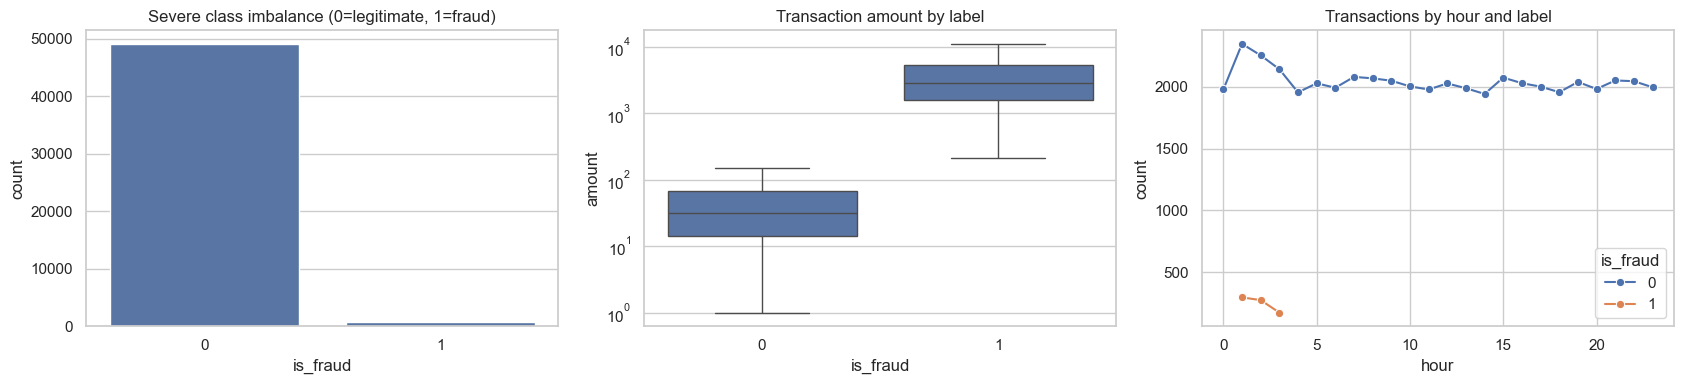

In [3]:
# Describe distributions by known label for audit only; these labels never enter model features.
profile = tx.groupby("is_fraud")["amount"].agg(
    count="count", mean="mean", median="median", std="std", min="min", max="max"
)
profile["q1"] = tx.groupby("is_fraud")["amount"].quantile(0.25)
profile["q3"] = tx.groupby("is_fraud")["amount"].quantile(0.75)
profile["iqr"] = profile["q3"] - profile["q1"]
profile["iqr_outlier_count"] = 0
for label, group in tx.groupby("is_fraud"):
    q1, q3 = group["amount"].quantile([0.25, 0.75])
    iqr = q3 - q1
    profile.loc[label, "iqr_outlier_count"] = int(((group["amount"] < q1 - 1.5 * iqr) |
                                                     (group["amount"] > q3 + 1.5 * iqr)).sum())
display(profile)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(data=tx, x="is_fraud", ax=axes[0])
axes[0].set_title("Severe class imbalance (0=legitimate, 1=fraud)")
sns.boxplot(data=tx, x="is_fraud", y="amount", showfliers=False, ax=axes[1])
axes[1].set_title("Transaction amount by label")
axes[1].set_yscale("log")
hour_counts = tx.assign(hour=tx["timestamp"].dt.hour).groupby(["hour", "is_fraud"]).size().rename("count").reset_index()
sns.lineplot(data=hour_counts, x="hour", y="count", hue="is_fraud", marker="o", ax=axes[2])
axes[2].set_title("Transactions by hour and label")
plt.tight_layout()
plt.show()

## 2. Leak-free historical feature engineering

For every account, rolling windows use `closed='left'`; the current transaction and future transactions are excluded. Features are computed in event-time order before the chronological split, which is valid because each row only sees history available at that event time.

In [4]:
tx = tx.merge(accounts, on="account_id", how="left", validate="many_to_one")
tx = tx.sort_values(["account_id", "timestamp", "transaction_id"], kind="mergesort").reset_index(drop=True)
tx["device_type"] = tx["device_type"].fillna("unknown")
tx["hour"] = tx["timestamp"].dt.hour
tx["hour_sin"] = np.sin(2 * np.pi * tx["hour"] / 24)
tx["hour_cos"] = np.cos(2 * np.pi * tx["hour"] / 24)
tx["is_late_night"] = tx["hour"].between(1, 4).astype("int8")
tx["is_foreign_tx"] = tx["is_foreign_tx"].astype("int8")
tx["amount_to_prior_avg_30d"] = np.nan
tx["tx_count_prior_1h"] = 0.0
tx["tx_count_prior_24h"] = 0.0
tx["minutes_since_prior_tx"] = np.nan

for _, row_indexes in tx.groupby("account_id", sort=False).groups.items():
    g = tx.loc[row_indexes].sort_values(["timestamp", "transaction_id"], kind="mergesort")
    time_indexed = g.set_index("timestamp")
    # closed='left' excludes current-row values; sorted data ensures no future event contributes.
    tx.loc[g.index, "tx_count_prior_1h"] = time_indexed["transaction_id"].rolling("1h", closed="left").count().to_numpy()
    tx.loc[g.index, "tx_count_prior_24h"] = time_indexed["transaction_id"].rolling("24h", closed="left").count().to_numpy()
    prior_avg = time_indexed["amount"].rolling("30D", closed="left").mean().to_numpy()
    tx.loc[g.index, "amount_to_prior_avg_30d"] = g["amount"].to_numpy() / np.maximum(prior_avg, 1.0)
    tx.loc[g.index, "minutes_since_prior_tx"] = g["timestamp"].diff().dt.total_seconds().div(60).to_numpy()

# Cold-start accounts have no transaction history; use an account-profile prior, not future transactions.
tx["tx_count_prior_1h"] = tx["tx_count_prior_1h"].fillna(0)
tx["tx_count_prior_24h"] = tx["tx_count_prior_24h"].fillna(0)
cold_start = tx["amount_to_prior_avg_30d"].isna()
tx.loc[cold_start, "amount_to_prior_avg_30d"] = (
    tx.loc[cold_start, "amount"] / (tx.loc[cold_start, "avg_monthly_spend"].div(30).clip(lower=1.0))
)
tx["minutes_since_prior_tx"] = tx["minutes_since_prior_tx"].fillna(60 * 24 * 30).clip(upper=60 * 24 * 30)

numeric_features = ["amount", "account_age_days", "avg_monthly_spend", "is_foreign_tx",
                    "tx_count_prior_1h", "tx_count_prior_24h", "amount_to_prior_avg_30d",
                    "minutes_since_prior_tx", "hour_sin", "hour_cos", "is_late_night"]
categorical_features = ["merchant_category", "device_type", "country_code", "kyc_tier", "home_country"]
feature_columns = numeric_features + categorical_features
assert tx[feature_columns].notna().all().all(), "Feature matrix contains nulls after cold-start handling"
tx[["transaction_id", "account_id", "timestamp"] + feature_columns + ["is_fraud"]].head()

,transaction_id,account_id,timestamp,amount,account_age_days,avg_monthly_spend,is_foreign_tx,tx_count_prior_1h,tx_count_prior_24h,amount_to_prior_avg_30d,minutes_since_prior_tx,hour_sin,hour_cos,is_late_night,merchant_category,device_type,country_code,kyc_tier,home_country,is_fraud
0,T0034882,A00000,2025-01-03 08:38:00+00:00,267.62,471,3254.29,0,0.0,0.0,2.467082,43200.0,0.866025,-0.500000,0,grocery,mobile,DE,standard,DE,0
1,T0042977,A00000,2025-01-07 02:26:00+00:00,6.54,471,3254.29,0,0.0,0.0,0.024438,5388.0,0.500000,0.866025,1,travel,pos,DE,standard,DE,0
2,T0003390,A00000,2025-01-08 22:39:00+00:00,2.37,471,3254.29,0,0.0,0.0,0.017289,2653.0,-0.500000,0.866025,0,retail,web,DE,standard,DE,0
3,T0022041,A00000,2025-01-11 14:27:00+00:00,87.91,471,3254.29,0,0.0,0.0,0.953712,3828.0,-0.500000,-0.866025,0,grocery,web,DE,standard,DE,0
4,T0032417,A00000,2025-01-14 17:48:00+00:00,59.67,471,3254.29,0,0.0,0.0,0.654923,4521.0,-0.965926,-0.258819,0,restaurants,mobile,DE,standard,DE,0


## 3. Chronological train / validation / test split

A global time split approximates deployment on future transactions. The validation and test samples retain their natural class prevalence. SMOTE is inside an imbalanced-learn pipeline, so it is fit only on training rows.

In [5]:
time_order = tx.sort_values(["timestamp", "transaction_id"], kind="mergesort").reset_index(drop=True)
n = len(time_order)
train_end, valid_end = int(n * 0.70), int(n * 0.85)
train = time_order.iloc[:train_end].copy()
valid = time_order.iloc[train_end:valid_end].copy()
test = time_order.iloc[valid_end:].copy()
for split_name, part in [("train", train), ("validation", valid), ("test", test)]:
    print(f"{split_name:10s}: {len(part):,} rows, {part['is_fraud'].mean():.3%} fraud, "
          f"{part['timestamp'].min()} — {part['timestamp'].max()}")
assert train["timestamp"].max() <= valid["timestamp"].min()
assert valid["timestamp"].max() <= test["timestamp"].min()
X_train, y_train = train[feature_columns], train["is_fraud"].astype(int)
X_valid, y_valid = valid[feature_columns], valid["is_fraud"].astype(int)
X_test, y_test = test[feature_columns], test["is_fraud"].astype(int)

numeric_pipe = SkPipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
categorical_pipe = SkPipeline([("impute", SimpleImputer(strategy="most_frequent")),
                               ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_pipe, numeric_features),
                                  ("cat", categorical_pipe, categorical_features)])

train     : 34,825 rows, 1.505% fraud, 2025-01-01 00:02:00+00:00 — 2025-03-05 06:13:00+00:00
validation: 7,462 rows, 1.488% fraud, 2025-03-05 06:14:00+00:00 — 2025-03-18 12:33:00+00:00
test      : 7,463 rows, 1.487% fraud, 2025-03-18 12:33:00+00:00 — 2025-03-31 23:59:00+00:00


## 4. Train weighting and resampling alternatives

The comparison includes class-weighted Logistic Regression, Decision Tree, and Random Forest, plus a Feed-Forward Neural Network trained with training-only SMOTE. A separate SMOTE Logistic Regression provides a direct resampling-vs-weighting comparison. The validation/test distributions are never altered.

In [6]:
candidates = {
    "Logistic Regression (balanced)": SkPipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE))]),
    "Decision Tree (balanced)": SkPipeline([
        ("preprocess", preprocessor),
        ("model", DecisionTreeClassifier(class_weight="balanced", max_depth=12,
                                         min_samples_leaf=20, random_state=RANDOM_STATE))]),
    "Random Forest (balanced)": SkPipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(n_estimators=180, min_samples_leaf=5,
                                         class_weight="balanced_subsample", n_jobs=-1,
                                         random_state=RANDOM_STATE))]),
    "MLP (training-only SMOTE)": ImbPipeline([
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
        ("model", MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu",
                                early_stopping=True, max_iter=100, random_state=RANDOM_STATE))]),
    "Logistic Regression (training-only SMOTE)": ImbPipeline([
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
}
valid_scores = {}
for name, estimator in candidates.items():
    print(f"Fitting {name}...")
    estimator.fit(X_train, y_train)
    valid_scores[name] = estimator.predict_proba(X_valid)[:, 1]
print("All model fits complete.")

Fitting Logistic Regression (balanced)...
Fitting Decision Tree (balanced)...
Fitting Random Forest (balanced)...
Fitting MLP (training-only SMOTE)...
Fitting Logistic Regression (training-only SMOTE)...
All model fits complete.


## 5. PR-AUC and capacity-constrained alert policy

Average precision (PR-AUC) is reported because accuracy is misleading at this prevalence. Each candidate is evaluated at the validation operating point that flags the highest-risk `ceil(2% × daily volume)` rows. Candidate selection maximizes validation fraud-loss capture less a configurable review cost, with PR-AUC as the tie-breaker. This uses labels for offline evaluation only; live queues are ranked by score.

,model,pr_auc,precision_at_capacity,recall_at_capacity,f1_at_capacity,alerts,captured_fraud_loss,estimated_net_value
0,Logistic Regression (training-only SMOTE),0.998865,0.751773,0.954955,0.841270,141,483672.82,481557.82
1,Logistic Regression (balanced),0.998291,0.744681,0.945946,0.833333,141,483164.09,481049.09
2,MLP (training-only SMOTE),0.998510,0.751773,0.954955,0.841270,141,482224.92,480109.92
3,Decision Tree (balanced),0.986873,0.744681,0.945946,0.833333,141,480565.03,478450.03
4,Random Forest (balanced),0.998700,0.744681,0.945946,0.833333,141,478793.52,476678.52


Selected on validation net value with PR-AUC tie-break: Logistic Regression (training-only SMOTE)


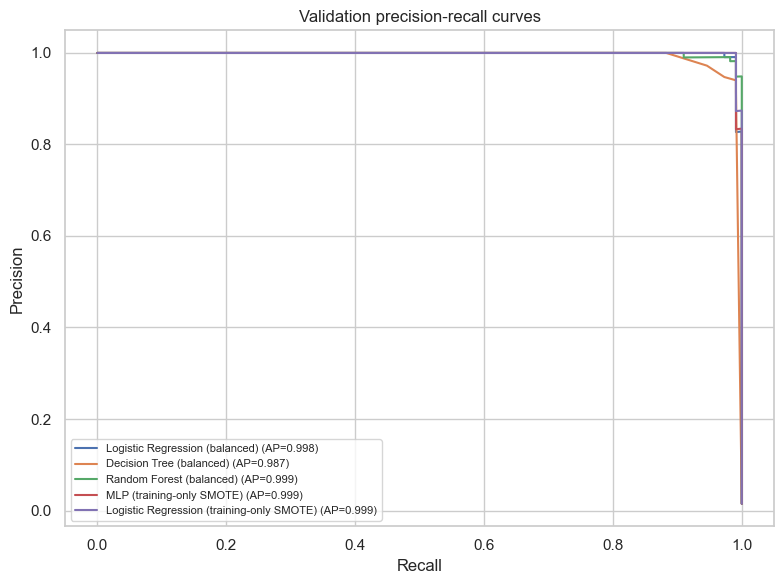

In [7]:
REVIEW_CAPACITY_RATE = 0.02
REVIEW_COST = 15.0  # assumed analyst handling cost in currency units per alert

def daily_capacity_selection(frame, scores, capacity_rate=REVIEW_CAPACITY_RATE):
    """Return 1-based daily ranks and a top-k flag that never exceeds daily capacity."""
    ranked = frame[["transaction_id", "timestamp"]].copy()
    ranked["risk_score"] = np.asarray(scores)
    ranked["date"] = ranked["timestamp"].dt.date
    ranked = ranked.sort_values(["date", "risk_score", "transaction_id"],
                                ascending=[True, False, True], kind="mergesort")
    ranked["alert_rank_daily"] = ranked.groupby("date").cumcount() + 1
    daily_n = ranked.groupby("date")["transaction_id"].transform("size")
    ranked["daily_capacity"] = np.floor(daily_n * capacity_rate).astype(int)
    ranked["alert_flag"] = (ranked["alert_rank_daily"] <= ranked["daily_capacity"]).astype("int8")
    ranked["daily_score_threshold"] = ranked["risk_score"].where(
        ranked["alert_rank_daily"] == ranked["daily_capacity"]
    ).groupby(ranked["date"]).transform("max")
    return ranked.set_index("transaction_id")[["risk_score", "alert_rank_daily", "daily_capacity",
                                                "daily_score_threshold", "alert_flag"]]

validation_rows = []
for name, scores in valid_scores.items():
    selection = daily_capacity_selection(valid, scores)
    flagged = selection.loc[valid["transaction_id"], "alert_flag"].to_numpy().astype(bool)
    ap = average_precision_score(y_valid, scores)
    captured_loss = float(valid.loc[flagged & (y_valid.to_numpy() == 1), "amount"].sum())
    review_cost = float(flagged.sum() * REVIEW_COST)
    y_hat = flagged.astype(int)
    validation_rows.append({
        "model": name, "pr_auc": ap,
        "precision_at_capacity": precision_score(y_valid, y_hat, zero_division=0),
        "recall_at_capacity": recall_score(y_valid, y_hat, zero_division=0),
        "f1_at_capacity": f1_score(y_valid, y_hat, zero_division=0),
        "alerts": int(flagged.sum()), "captured_fraud_loss": captured_loss,
        "estimated_net_value": captured_loss - review_cost,
    })
validation_metrics = pd.DataFrame(validation_rows).sort_values(
    ["estimated_net_value", "pr_auc"], ascending=False).reset_index(drop=True)
display(validation_metrics)
selected_model_name = validation_metrics.iloc[0]["model"]
selected_model = candidates[selected_model_name]
print(f"Selected on validation net value with PR-AUC tie-break: {selected_model_name}")

plt.figure(figsize=(8, 6))
for name, scores in valid_scores.items():
    precision, recall, _ = precision_recall_curve(y_valid, scores)
    plt.plot(recall, precision, label=f"{name} (AP={average_precision_score(y_valid, scores):.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation precision-recall curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Untouched test evaluation and operational exports

The chosen model is evaluated once on the natural-prevalence test set. Daily ranking implements the analyst capacity rule and avoids relying on a single global threshold when daily volume varies. A simulated outcome is generated only for demonstration: in production the outcome must come from an investigator, with uncertainty/escalation states supported.

In [8]:
test_scores = selected_model.predict_proba(X_test)[:, 1]
test_selection = daily_capacity_selection(test, test_scores)
test_results = test[["transaction_id", "account_id", "timestamp", "amount"]].copy()
test_results = test_results.join(test_selection, on="transaction_id")
test_results["model_version"] = selected_model_name
test_results["date"] = test_results["timestamp"].dt.date
y_test_hat = test_results["alert_flag"].astype(int).to_numpy()
test_ap = average_precision_score(y_test, test_scores)
test_summary = {
    "test_pr_auc": test_ap,
    "precision_at_capacity": precision_score(y_test, y_test_hat, zero_division=0),
    "recall_at_capacity": recall_score(y_test, y_test_hat, zero_division=0),
    "f1_at_capacity": f1_score(y_test, y_test_hat, zero_division=0),
    "alerts": int(y_test_hat.sum()),
    "alert_rate": float(y_test_hat.mean()),
}
print(test_summary)
print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
print(confusion_matrix(y_test, y_test_hat, labels=[0, 1]))
print(classification_report(y_test, y_test_hat, target_names=["legitimate", "fraud"], zero_division=0))

scores_export = test_results[["transaction_id", "account_id", "timestamp", "amount", "risk_score",
                              "daily_score_threshold",
                              "alert_flag", "alert_rank_daily", "daily_capacity", "model_version"]].copy()
alerts_export = scores_export.loc[scores_export["alert_flag"] == 1].sort_values(
    ["timestamp", "alert_rank_daily"])
# Synthetic-only label simulation: an alert is confirmed when its generated ground truth is fraud.
alert_labels = test.set_index("transaction_id")["is_fraud"]
outcomes = alerts_export[["transaction_id", "account_id", "timestamp", "amount", "risk_score"]].copy()
outcomes["reviewed_at"] = outcomes["timestamp"] + pd.Timedelta(hours=4)
outcomes["outcome"] = np.where(alert_labels.loc[outcomes["transaction_id"]].to_numpy() == 1,
                               "confirmed_fraud", "false_positive")
outcomes["prevented_loss"] = np.where(outcomes["outcome"] == "confirmed_fraud", outcomes["amount"], 0.0)
outcomes["reviewer_id"] = "SIMULATED_REVIEWER"
outcomes["outcome_source"] = "synthetic_ground_truth_demo"

scores_export.to_csv(PROCESSED_DIR / "scored_transactions.csv", index=False)
alerts_export.to_csv(PROCESSED_DIR / "alert_queue.csv", index=False)
outcomes.to_csv(PROCESSED_DIR / "investigation_outcomes.csv", index=False)
validation_metrics.to_csv(PROCESSED_DIR / "validation_model_metrics.csv", index=False)
pd.DataFrame([test_summary]).assign(model=selected_model_name).to_csv(
    PROCESSED_DIR / "test_model_metrics.csv", index=False)
print(f"Exported scored rows={len(scores_export):,}, alerts={len(alerts_export):,}, "
      f"simulated outcomes={len(outcomes):,} to {PROCESSED_DIR.resolve()}")

{'test_pr_auc': 0.9927618465102938, 'precision_at_capacity': 0.7291666666666666, 'recall_at_capacity': 0.9459459459459459, 'f1_at_capacity': 0.8235294117647058, 'alerts': 144, 'alert_rate': 0.019295189602036713}
Confusion matrix [ [TN, FP], [FN, TP] ]:
[[7313   39]
 [   6  105]]
              precision    recall  f1-score   support

  legitimate       1.00      0.99      1.00      7352
       fraud       0.73      0.95      0.82       111

    accuracy                           0.99      7463
   macro avg       0.86      0.97      0.91      7463
weighted avg       1.00      0.99      0.99      7463

Exported scored rows=7,463, alerts=144, simulated outcomes=144 to D:\cogniza internship data science project\project 4\data\processed


### Interpretation and production controls

- Use PR-AUC and precision/recall at the declared review capacity; do not optimize accuracy on this imbalanced population.
- The offline simulated investigation outcomes are not operational truth. Replace them with controlled, timestamped human review outcomes before production measurement or retraining.
- Risk scores prioritize review only. A score or alert does not establish fraud, authorize adverse account action, or replace investigator judgment and required customer/regulatory processes.
- Before deployment, add probability calibration, drift and fairness monitoring, access controls, model/version governance, reproducible artifact storage, and a rollback path.